# DPO en Kaggle (IIC-3694, camino 5)

Entrena Qwen3-1.7B con DPO y LoRA sobre los pares (correcta, incorrecta) del conjunto combinado y deja las **curvas de pérdida, margen y exactitud de preferencia**.

Qué hace:
1. Usa las dos GPU T4 en paralelo: una corrida por GPU, cada una con su semilla (2026 y 2027), igual que el piloto de GRPO.
2. Entrena por omisión solo con los pares de la condición `visible` (262 de 635): así la pérdida no cubre el mensaje con los resultados de la herramienta, y el resultado se compara directo con GRPO y con la evaluación en `visible`.
3. Descarta los pares que no caben en `LARGO` tokens en vez de truncarlos (truncar puede cortar el `<answer>`).
4. Se detiene solo a los `MINUTOS` configurados si no terminó antes, y guarda el adaptador igual.

**Cómo usarlo:** *Settings*: **GPU T4 x2** e **Internet On**; *Add Input*: el dataset con el zip del código (`dist/inventory_harness_colab.zip`, rama `dpo-kaggle` o posterior). Los pares (`dpo.jsonl`) se buscan en la entrada; si no están, se descargan del repositorio en un commit fijo y se verifica su huella. *Save Version > Save & Run All (Commit)*: corre en segundo plano aunque se cierre el navegador. Al terminar, en *Output* están `curva_margen.png`, `curva_perdida.png` y `resultados_dpo.zip`.

Para medir los adaptadores en `eval`, usa `evaluar_grpo_kaggle.ipynb` con `METODO = "dpo"` y `resultados_dpo.zip` como entrada.

## 1. GPU

In [1]:
import os
import time

INICIO = time.time()
PRUEBA_SECA = os.environ.get("PRUEBA_SECA") == "1"  # solo para probar el cuaderno sin GPU

if PRUEBA_SECA:
    N_GPU = 0
else:
    import torch

    N_GPU = torch.cuda.device_count()
    for i in range(N_GPU):
        props = torch.cuda.get_device_properties(i)
        print(f"GPU {i}: {props.name} ({props.total_memory / 2**30:.1f} GiB)")
    if N_GPU == 0:
        raise SystemExit("No hay GPU. Settings > Accelerator > GPU T4 x2.")
    if N_GPU == 1:
        print("Hay una sola GPU: se entrena una sola semilla. Con T4 x2 se entrenan dos en paralelo.")

GPU 0: Tesla T4 (14.6 GiB)
GPU 1: Tesla T4 (14.6 GiB)


## 2. Código

Busca en `/kaggle/input` el zip del proyecto (debe traer `scripts/train_dpo.py` con `--drop-longer`), aunque Kaggle lo haya descomprimido o el navegador lo haya renombrado.

In [2]:
import shutil
import sys
import zipfile
from pathlib import Path

ENTRADA = Path(os.environ.get("ENTRADA_KAGGLE", "/kaggle/input"))
SALIDA = Path(os.environ.get("SALIDA_KAGGLE", "/kaggle/working"))
CODIGO = Path(os.environ.get("CODIGO_KAGGLE", "/tmp/inventory_harness"))
ZIPS = CODIGO.parent / "entrada_zips"
SALIDA.mkdir(parents=True, exist_ok=True)


def archivos(raiz):
    # os.walk siguiendo enlaces: en Kaggle /kaggle/input puede tener carpetas enlazadas.
    for carpeta, _, nombres in os.walk(raiz, followlinks=True):
        for nombre in nombres:
            yield Path(carpeta) / nombre


def mostrar_entrada():
    print("Contenido de", ENTRADA, "(primeros 60 archivos):")
    for i, ruta in enumerate(sorted(archivos(ENTRADA))):
        if i == 60:
            print("  ...")
            break
        print("  ", ruta)


def es_codigo(raiz):
    script = raiz / "scripts" / "train_dpo.py"
    return (script.exists() and "--drop-longer" in script.read_text(encoding="utf-8")
            and (raiz / "src" / "inventory_harness").is_dir())


shutil.rmtree(ZIPS, ignore_errors=True)
for i, ruta in enumerate(sorted(r for r in archivos(ENTRADA) if r.suffix.lower() == ".zip")):
    try:
        with zipfile.ZipFile(ruta) as archivo:
            if any(n.endswith("scripts/train_dpo.py") for n in archivo.namelist()):
                archivo.extractall(ZIPS / f"zip{i}")
                print("Descomprimido", ruta)
    except zipfile.BadZipFile:
        pass

origen = None
for raiz in (ENTRADA, ZIPS):
    for script in sorted(r for r in archivos(raiz) if r.as_posix().endswith("scripts/train_dpo.py")):
        if es_codigo(script.parent.parent):
            origen = script.parent.parent
            break
    if origen:
        break
if origen is None:
    mostrar_entrada()
    raise SystemExit("No encontre el codigo con scripts/train_dpo.py y --drop-longer. Revisa que el dataset "
                     "tenga el zip NUEVO (rama dpo-kaggle) y que este agregado con Add Input.")
shutil.rmtree(CODIGO, ignore_errors=True)
shutil.copytree(origen, CODIGO)
print("Codigo desde", origen)

Codigo desde /kaggle/input/datasets/tomasariztia/inventory


## 3. Dependencias

Versiones con las que se probaron los scripts (`requirements-train.txt`). Si no se pueden instalar, se prueba sin fijarlas, y entonces los scripts podrían necesitar ajustes menores.

In [3]:
import subprocess

PAQUETES = ["transformers==5.24.0", "trl==1.18.2", "peft==0.22.0", "accelerate==1.16.0",
            "datasets==5.2.0", "jinja2>=3.1.6", "matplotlib"]
if not PRUEBA_SECA:
    hecho = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PAQUETES])
    if hecho.returncode != 0:
        print("Fallo la instalacion con versiones fijas; se prueba sin fijarlas.")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "trl", "peft",
                        "accelerate", "datasets", "jinja2>=3.1.6", "matplotlib"], check=True)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


## 4. Pares DPO

El zip del código no trae `results/`. Se usa un `dpo.jsonl` de la entrada si hay uno; si no, se descarga el conjunto combinado del repositorio en el commit `7dd2db8` y se verifica su huella SHA-256.

In [4]:
import hashlib
import urllib.request

URL_DPO = ("https://raw.githubusercontent.com/tariztia/harness-inventarios/"
           "7dd2db8314b16c24cd15832ad1e8d018fb4c9a75/results/datos_combinados/dpo.jsonl")
HUELLA_DPO = "54fa530cac809f6b89c087a7fa03a122de9ba572469d8743d446407e95cf06f7"
DATOS = CODIGO / "results" / "datos_combinados" / "dpo.jsonl"
DATOS.parent.mkdir(parents=True, exist_ok=True)


def huella(ruta):
    return hashlib.sha256(ruta.read_bytes()).hexdigest()


en_entrada = sorted(r for r in archivos(ENTRADA) if r.name == "dpo.jsonl")
if en_entrada:
    shutil.copy(en_entrada[0], DATOS)
    print("Pares desde la entrada:", en_entrada[0])
    if huella(DATOS) != HUELLA_DPO:
        print("Aviso: la huella no es la del conjunto combinado de 7dd2db8; se usa igual.")
else:
    urllib.request.urlretrieve(URL_DPO, DATOS)
    assert huella(DATOS) == HUELLA_DPO, "La huella del dpo.jsonl descargado no coincide."
    print("Pares descargados y verificados:", DATOS)

import json
from collections import Counter

filas = [json.loads(l) for l in DATOS.read_text(encoding="utf-8").splitlines() if l.strip()]
print(len(filas), "pares;", dict(Counter(f["condition"] for f in filas)), dict(Counter(f["difficulty"] for f in filas)))

Pares descargados y verificados: /tmp/inventory_harness/results/datos_combinados/dpo.jsonl
635 pares; {'tools': 373, 'visible': 262} {'easy': 124, 'hard': 283, 'medium': 228}


## 5. Configuración

Todo lo que se puede editar está en este bloque.

- **`CONDICION`**: `visible` (262 pares, por omisión), `tools` o `all` (635 pares, unas 3 veces más lento).
- **`EPOCAS`**: con `visible` y 3 épocas son unos 49 pasos de optimización; se estimó 1 hora a 1 hora y 15 minutos por corrida en una T4 (no medido: el tiempo real aparece en el log).
- **`MINUTOS`**: tope de seguridad por corrida, sin contar la carga del modelo. Si se cumple, guarda el adaptador con lo hecho.
- **`LARGO`**: tokens de prompt más respuesta. Los pares más largos se descartan (en `visible` son unos 6).
- **`POR_GPU` y `ACUM`**: 1 × 16 = 16 pares por paso, como el valor por omisión del script (4 × 4) pero con menos memoria.

In [5]:
# ----------------------------- Editar aqui -----------------------------
MODELO = "Qwen/Qwen3-1.7B"
SEMILLAS = [2026, 2027]        # una por GPU; con una sola GPU corre solo la primera
CONDICION = "visible"
EPOCAS = 3
MINUTOS = 150
LARGO = 4096
TASA = 2e-5                    # tasa de aprendizaje de LoRA
BETA = 0.1                     # fuerza de la restriccion al modelo de referencia
POR_GPU = 1                    # pares por pasada en cada GPU (memoria)
ACUM = 16                      # pasadas por paso de optimizacion
MAX_PASOS = -1                 # -1 = sin tope (manda EPOCAS o MINUTOS)
LIMITE = None                  # humo: usar solo los primeros N pares
# ------------------------------------------------------------------------

if PRUEBA_SECA:  # humo en CPU con un modelo diminuto
    MODELO, MINUTOS, LARGO, MAX_PASOS, LIMITE, ACUM = "Qwen/Qwen3-0.6B", 5, 2048, 2, 4, 2

USAR = SEMILLAS if PRUEBA_SECA else SEMILLAS[: max(1, N_GPU)]
RUNS = SALIDA / "runs"
LOGS = SALIDA / "logs"
print(f"Modelo {MODELO}; semillas {USAR}; condicion {CONDICION}; {EPOCAS} epocas; tope {MINUTOS} min; "
      f"largo {LARGO}; {POR_GPU * ACUM} pares por paso; beta {BETA}; tasa {TASA}")

Modelo Qwen/Qwen3-1.7B; semillas [2026, 2027]; condicion visible; 3 epocas; tope 150 min; largo 4096; 16 pares por paso; beta 0.1; tasa 2e-05


## 6. Entrenar

Descarga el modelo y lanza una corrida por GPU. Cada ~minuto se imprime el último paso registrado de cada una: pérdida, exactitud de preferencia (fracción de pares donde la correcta queda por encima de la incorrecta), margen y minutos transcurridos. Al partir, la pérdida es ~0,69 (ln 2) y la exactitud ~0,5.

In [6]:
import re

if not PRUEBA_SECA:
    subprocess.run([sys.executable, "-c",
                    f"from huggingface_hub import snapshot_download; snapshot_download({MODELO!r})"], check=True)


def valor(fila, clave):
    try:
        return float(fila[clave])
    except (KeyError, TypeError, ValueError):
        return float("nan")


def resumen(fila):
    return (f"perdida {valor(fila, 'loss'):.3f} | exactitud {valor(fila, 'rewards/accuracies'):.2f} | "
            f"margen {valor(fila, 'rewards/margins'):.3f} | epoca {valor(fila, 'epoch'):.2f} | "
            f"{valor(fila, 'minutos'):.1f} min")


shutil.rmtree(RUNS, ignore_errors=True)
LOGS.mkdir(parents=True, exist_ok=True)
corridas = []
for indice, semilla in enumerate(USAR):
    carpeta = RUNS / f"dpo_s{semilla}"
    orden = [sys.executable, "-u", "scripts/train_dpo.py", "--model", MODELO, "--out", carpeta,
             "--data", DATOS, "--condition", CONDICION, "--seed", semilla, "--epochs", EPOCAS,
             "--batch-size", POR_GPU, "--grad-accum", ACUM, "--learning-rate", TASA, "--beta", BETA,
             "--max-length", LARGO, "--drop-longer", "--max-steps", MAX_PASOS, "--max-minutes", MINUTOS,
             "--gradient-checkpointing", "--logging-steps", 1]
    if LIMITE:
        orden += ["--limit", LIMITE]
    entorno = dict(os.environ)
    if not PRUEBA_SECA:
        entorno["CUDA_VISIBLE_DEVICES"] = str(indice)  # una GPU por corrida
    ruta = LOGS / f"s{semilla}.log"
    manejador = open(ruta, "w")
    proceso = subprocess.Popen([str(x) for x in orden], cwd=CODIGO, env=entorno,
                               stdout=manejador, stderr=subprocess.STDOUT, text=True)
    corridas.append({"semilla": semilla, "proceso": proceso, "ruta": ruta, "carpeta": carpeta,
                     "visto": 0, "filas": 0})
    print(f"Corrida con semilla {semilla} en la GPU {indice}")

limite_duro = time.time() + (MINUTOS + 45) * 60
ultimo_latido = time.time()
while any(c["proceso"].poll() is None for c in corridas):
    time.sleep(2 if PRUEBA_SECA else 60)
    for c in corridas:
        texto = c["ruta"].read_text(errors="replace")
        nuevo, c["visto"] = texto[c["visto"]:], len(texto)
        for linea in re.split(r"[\r\n]+", nuevo):
            if linea.startswith(("DPO:", "Se cumplieron", "Adaptador guardado")) or "OutOfMemory" in linea:
                print(f"[s{c['semilla']}] {linea}", flush=True)
        registro = c["carpeta"] / "log.jsonl"
        if registro.exists():
            filas = [json.loads(l) for l in registro.read_text(encoding="utf-8").splitlines() if l.strip()]
            pasos = [f for f in filas if "rewards/margins" in f]
            if len(pasos) > c["filas"]:
                c["filas"] = len(pasos)
                print(f"[s{c['semilla']}] paso {pasos[-1]['paso']}: {resumen(pasos[-1])}", flush=True)
    if time.time() - ultimo_latido > 600:
        ultimo_latido = time.time()
        print(f"... {(time.time() - INICIO) / 60:.0f} min desde el inicio; pasos: "
              + ", ".join(f"s{c['semilla']}={c['filas']}" for c in corridas), flush=True)
    if time.time() > limite_duro:
        print("Se paso del limite duro de tiempo: se detienen las corridas.")
        for c in corridas:
            c["proceso"].terminate()
        break

for c in corridas:
    c["proceso"].wait()
    codigo = c["proceso"].returncode
    print(f"Semilla {c['semilla']} termino con codigo {codigo}; {c['filas']} pasos registrados.")
    if codigo != 0:
        print("--- ultimas lineas del log ---")
        print("\n".join(c["ruta"].read_text(errors="replace").splitlines()[-40:]))
print(f"Tiempo total: {(time.time() - INICIO) / 60:.0f} min")

Fetching 12 files: 100%|██████████| 12/12 [00:25<00:00,  2.09s/it]


Corrida con semilla 2026 en la GPU 0
Corrida con semilla 2027 en la GPU 1
[s2026] DPO: {'pares': 230, 'descartados_por_largo': 32}
[s2027] DPO: {'pares': 230, 'descartados_por_largo': 32}
[s2026] paso 1: perdida 0.693 | exactitud 0.00 | margen 0.000 | epoca 0.07 | 1.2 min
[s2027] paso 1: perdida 0.693 | exactitud 0.00 | margen 0.000 | epoca 0.07 | 1.7 min
[s2026] paso 2: perdida 0.693 | exactitud 0.00 | margen 0.000 | epoca 0.14 | 3.2 min
[s2027] paso 2: perdida 0.693 | exactitud 0.00 | margen 0.000 | epoca 0.14 | 3.2 min
[s2026] paso 3: perdida 0.693 | exactitud 0.00 | margen 0.000 | epoca 0.21 | 5.1 min
[s2027] paso 3: perdida 0.693 | exactitud 0.00 | margen 0.000 | epoca 0.21 | 4.6 min
[s2027] paso 4: perdida 0.693 | exactitud 0.00 | margen 0.000 | epoca 0.28 | 5.7 min
[s2026] paso 4: perdida 0.693 | exactitud 0.00 | margen 0.000 | epoca 0.28 | 7.1 min
[s2027] paso 5: perdida 0.308 | exactitud 0.88 | margen 1.343 | epoca 0.35 | 7.6 min
[s2026] paso 5: perdida 0.284 | exactitud 0.94 

## 7. Curvas

DPO no tiene recompensa del harness durante el entrenamiento: sus curvas son la **pérdida**, el **margen** (log-probabilidad relativa de la correcta menos la de la incorrecta, escalada por `BETA`) y la **exactitud de preferencia**. Que el margen suba dice que el modelo aprende a preferir la respuesta correcta en los pares de entrenamiento; si eso mejora el pass@1 en `eval` se mide después con el cuaderno de evaluación.

Serie en /kaggle/working/curva_perdida.csv
Figura en /kaggle/working/curva_perdida.png
Serie en /kaggle/working/curva_margen.csv
Figura en /kaggle/working/curva_margen.png
Serie en /kaggle/working/curva_exactitud.csv
Figura en /kaggle/working/curva_exactitud.png


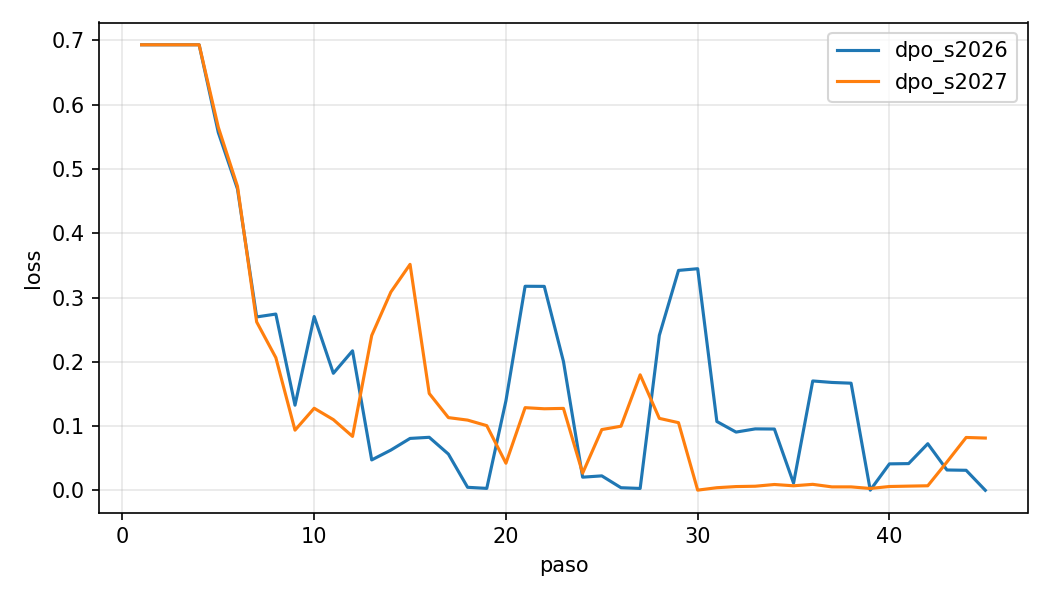

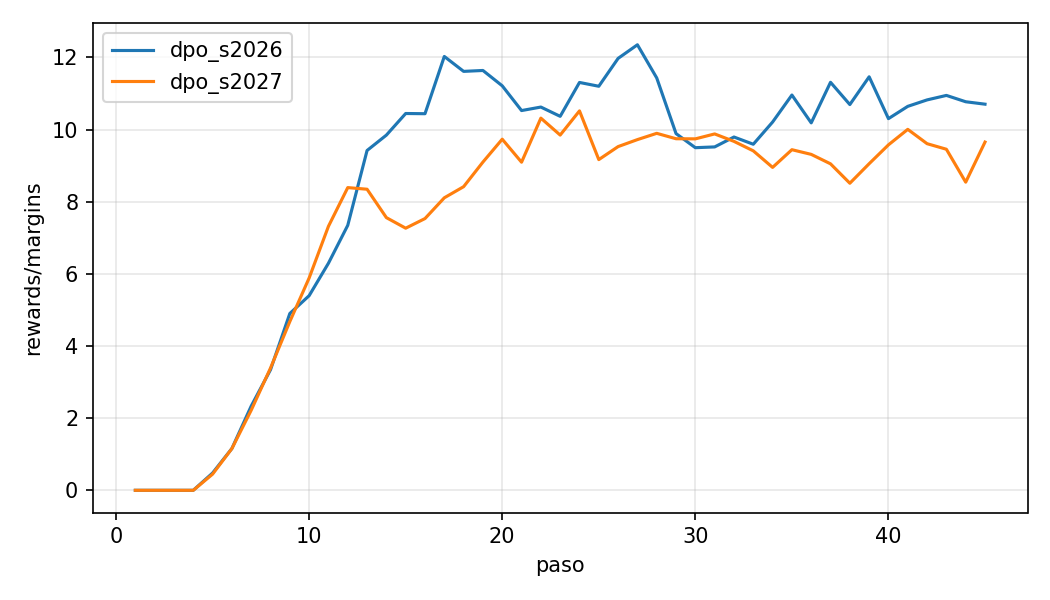

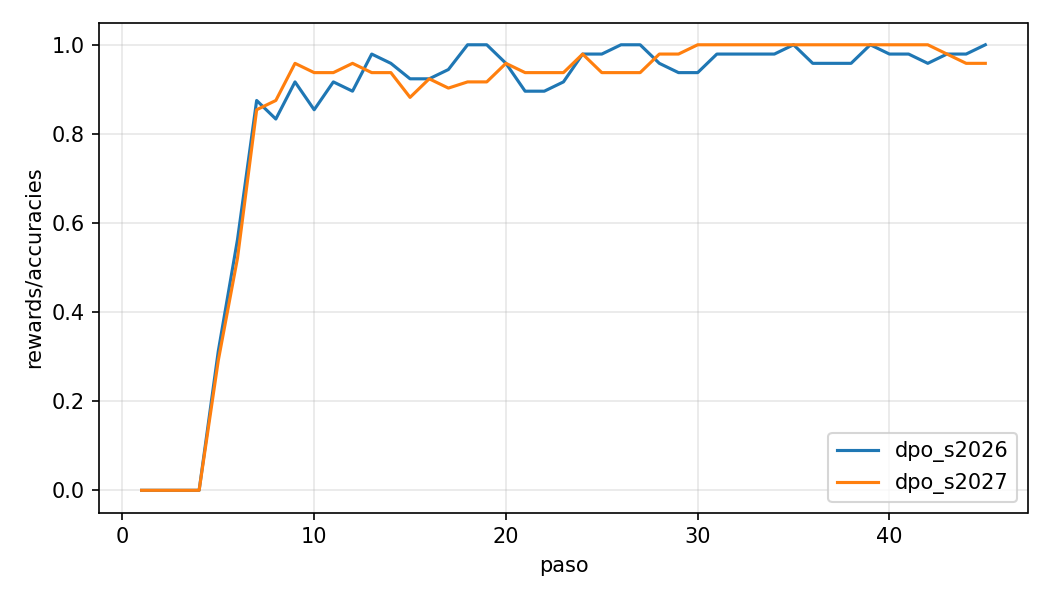

corrida | pasos | pares | perdida 1er tercio -> ultimo | exactitud 1er -> ultimo | margen 1er -> ultimo | detenida por tiempo
dpo_s2026 | 45 | 230 | 0.319 -> 0.068 | 0.66 -> 0.98 | 4.770 -> 10.552 | False
dpo_s2027 | 45 | 230 | 0.339 -> 0.022 | 0.66 -> 0.99 | 4.298 -> 9.406 | False


In [7]:
def historia(carpeta):
    final = carpeta / "train_log.json"
    if final.exists():
        return json.loads(final.read_text(encoding="utf-8"))
    parcial = carpeta / "log.jsonl"
    if parcial.exists():
        return [json.loads(l) for l in parcial.read_text(encoding="utf-8").splitlines() if l.strip()]
    return []


def media(filas, clave):
    valores = [valor(f, clave) for f in filas if clave in f]
    return sum(valores) / len(valores) if valores else float("nan")


CURVAS = (("loss", "curva_perdida.png"), ("rewards/margins", "curva_margen.png"),
          ("rewards/accuracies", "curva_exactitud.png"))
carpetas = [d for d in sorted(RUNS.glob("dpo_s*")) if any("rewards/margins" in f for f in historia(d))]
if not carpetas:
    print("No hay pasos registrados. Mira los logs de arriba (o en logs/).")
else:
    for metrica, nombre in CURVAS:
        subprocess.run([sys.executable, "scripts/plot_training.py", *map(str, carpetas), "--metric", metrica,
                        "--smooth", "3", "--out", str(SALIDA / nombre)], cwd=CODIGO, check=True)
    try:
        from IPython.display import Image, display

        for _, nombre in CURVAS:
            if (SALIDA / nombre).exists():
                display(Image(filename=str(SALIDA / nombre)))
    except ImportError:
        pass

    print("corrida | pasos | pares | perdida 1er tercio -> ultimo | exactitud 1er -> ultimo | margen 1er -> ultimo | detenida por tiempo")
    for carpeta in carpetas:
        filas = [f for f in historia(carpeta) if "rewards/margins" in f]
        tercio = max(1, len(filas) // 3)
        manifiesto = carpeta / "manifest.json"
        datos = json.loads(manifiesto.read_text(encoding="utf-8")) if manifiesto.exists() else {}
        print(f"{carpeta.name} | {len(filas)} | {datos.get('datos', {}).get('pares', '?')} | "
              f"{media(filas[:tercio], 'loss'):.3f} -> {media(filas[-tercio:], 'loss'):.3f} | "
              f"{media(filas[:tercio], 'rewards/accuracies'):.2f} -> {media(filas[-tercio:], 'rewards/accuracies'):.2f} | "
              f"{media(filas[:tercio], 'rewards/margins'):.3f} -> {media(filas[-tercio:], 'rewards/margins'):.3f} | "
              f"{datos.get('detenido_por_tiempo', '?')}")

## 8. Resultados en un zip

In [8]:
import datetime

ZIP = SALIDA / "resultados_dpo.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as archivo:
    for ruta in sorted(RUNS.rglob("*")):
        if ruta.is_file() and "trainer" not in ruta.relative_to(RUNS).parts:
            archivo.write(ruta, "runs/" + ruta.relative_to(RUNS).as_posix())
    for ruta in sorted(LOGS.glob("*.log")):
        archivo.write(ruta, "logs/" + ruta.name)
    for _, nombre in CURVAS:
        for extra in (nombre, nombre.replace(".png", ".csv")):
            if (SALIDA / extra).exists():
                archivo.write(SALIDA / extra, extra)
print(datetime.datetime.now().isoformat(timespec="seconds"))
print(f"LISTO ({ZIP.stat().st_size / 2**20:.0f} MiB): {ZIP}")
print("Descargalo desde la pestana Output de esta version. Para medirlo en eval: evaluar_grpo_kaggle.ipynb con METODO = 'dpo'.")

2026-11-25T21:53:20
LISTO (127 MiB): /kaggle/working/resultados_dpo.zip
Descargalo desde la pestana Output de esta version. Para medirlo en eval: evaluar_grpo_kaggle.ipynb con METODO = 'dpo'.
